# Fixed-seed repeatability: Batch A vs. Batch B

**Purpose:** assess whether two independent agent batches reproduce clustering results when both use LLM seed 42 and Leiden seed 42.

The notebook follows this sequence:
1. Load the two experiment trajectories.
2. Identify parameter configurations evaluated in both batches.
3. Compare cell-level cluster assignments for every matched evaluation pair.
4. Summarize repeatability checks and save results.
5. Compare the agent-selected final configurations and their cluster-size distributions.

**Important:** repeated parameter configurations create multiple matched evaluation pairs. These pairs are not all independent observations, so pair-level percentages should not be interpreted as independent-run reproducibility rates.

## 1. Imports and experiment paths

In [1]:
from pathlib import Path
import ast
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Run this notebook from the project root.
experiments_dir = Path.cwd() / "experiments"

batch_a_dir = experiments_dir / "llm_seed42_agent_repeatability_20261018_222712_094535"
batch_b_dir = experiments_dir / "llm_seed42_agent_repeatability_20261018_231507_970469"

batch_a_analysis_dir = batch_a_dir / "new_analysis_k9"
batch_b_analysis_dir = batch_b_dir / "new_analysis_k9"

PARAMS = ["n_neighbors", "n_pcs", "resolution"]
LEIDEN_SEED = 42

## 2. Load and standardize the trajectories

In [2]:
batch_a_trajectory = pd.read_csv(
    batch_a_analysis_dir / "new_iteration_trajectory_table.csv"
)
batch_b_trajectory = pd.read_csv(
    batch_b_analysis_dir / "new_iteration_trajectory_table.csv"
)

for df in (batch_a_trajectory, batch_b_trajectory):
    df["run_index"] = df["run_index"].astype(int)
    df["iteration"] = df["iteration"].astype(int)
    df["n_neighbors"] = df["n_neighbors"].astype(int)
    df["n_pcs"] = df["n_pcs"].astype(int)
    df["resolution"] = df["resolution"].astype(float).round(6)

print(f"Batch A evaluations: {len(batch_a_trajectory)}")
print(f"Batch B evaluations: {len(batch_b_trajectory)}")
print(f"Distinct configurations in Batch A: {len(batch_a_trajectory[PARAMS].drop_duplicates())}")
print(f"Distinct configurations in Batch B: {len(batch_b_trajectory[PARAMS].drop_duplicates())}")

Batch A evaluations: 99
Batch B evaluations: 109
Distinct configurations in Batch A: 82
Distinct configurations in Batch B: 83


## 3. Identify shared parameter configurations

In [3]:
configs_a = batch_a_trajectory[PARAMS].drop_duplicates()
configs_b = batch_b_trajectory[PARAMS].drop_duplicates()

shared_configs = (
    configs_a.merge(configs_b, on=PARAMS, how="inner")
    .sort_values(PARAMS)
    .reset_index(drop=True)
)

print(f"Shared distinct parameter configurations: {len(shared_configs)}")
display(shared_configs)

Shared distinct parameter configurations: 27


,n_neighbors,n_pcs,resolution
0,15,30,0.70
1,15,30,0.80
2,15,30,1.00
3,20,10,0.80
4,20,12,0.80
5,20,15,0.80
6,20,15,1.00
7,20,20,1.00
8,20,25,0.60
9,20,30,0.70


## 4. Load cell-level labels safely

The label and cell-ID arrays are paired by run and iteration. Cell IDs are used to align observations before ARI/NMI are calculated.

In [4]:
def load_iteration(run_dir, run_index, iteration):
    run_tag = f"REPEAT_{int(run_index):02d}_LSEED_{LEIDEN_SEED:02d}"
    iter_tag = f"{run_tag}_ITER_{int(iteration):02d}"

    label_files = list(run_dir.glob(f"*{iter_tag}_labels.npy"))
    id_files = list(run_dir.glob(f"*{iter_tag}_cell_ids.npy"))

    if len(label_files) != 1 or len(id_files) != 1:
        raise FileNotFoundError(
            f"Expected one label file and one cell-ID file for {iter_tag}. "
            f"Labels found: {[p.name for p in label_files]}; "
            f"cell IDs found: {[p.name for p in id_files]}"
        )

    labels = np.load(label_files[0], allow_pickle=True).ravel()
    cell_ids = np.load(id_files[0], allow_pickle=True).ravel()

    if len(labels) != len(cell_ids):
        raise ValueError(f"Label count and cell-ID count differ for {iter_tag}.")
    if pd.Index(cell_ids).has_duplicates:
        raise ValueError(f"Duplicate cell IDs detected for {iter_tag}.")

    return pd.Series(labels, index=pd.Index(cell_ids, name="cell_id"))

## 5. Match evaluations across batches

In [5]:
# Every pair of evaluations with the same parameter configuration is compared.
# A configuration repeated in either batch can contribute multiple pairs.
matched = batch_a_trajectory.merge(
    batch_b_trajectory,
    on=PARAMS,
    how="inner",
    suffixes=("_a", "_b"),
)

print(f"Matched evaluation pairs: {len(matched)}")
display(
    matched[PARAMS + ["run_index_a", "iteration_a", "run_index_b", "iteration_b"]]
    .head(10)
)

Matched evaluation pairs: 117


,n_neighbors,n_pcs,resolution,run_index_a,iteration_a,run_index_b,iteration_b
0,15,30,1.0,1,0,1,0
1,15,30,1.0,1,0,2,0
2,15,30,1.0,1,0,3,0
3,15,30,1.0,1,0,4,0
4,15,30,1.0,1,0,5,0
5,15,30,1.0,1,0,6,0
6,15,30,1.0,1,0,7,0
7,15,30,1.0,1,0,8,0
8,20,30,1.0,1,1,1,1
9,20,30,0.8,1,2,1,2


## 6. Compare cell-level partitions and recorded metrics

In [6]:
def compare_clusterings(labels_a, labels_b):
    same_cells = (
        len(labels_a) == len(labels_b)
        and set(labels_a.index) == set(labels_b.index)
    )
    if not same_cells:
        raise ValueError("The two evaluations do not contain the same cell IDs.")

    # Align by cell ID rather than assuming identical array order.
    labels_b = labels_b.reindex(labels_a.index)
    if labels_b.isna().any():
        raise ValueError("Missing labels after aligning by cell ID.")

    sizes_a = tuple(sorted(pd.Series(labels_a).value_counts().tolist(), reverse=True))
    sizes_b = tuple(sorted(pd.Series(labels_b).value_counts().tolist(), reverse=True))
    n_clusters_a = pd.Series(labels_a).nunique()
    n_clusters_b = pd.Series(labels_b).nunique()
    ari = adjusted_rand_score(labels_a, labels_b)
    nmi = normalized_mutual_info_score(labels_a, labels_b)

    return {
        "same_cell_ids": same_cells,
        "n_cells": len(labels_a),
        "clusters_from_labels_batch_a": n_clusters_a,
        "clusters_from_labels_batch_b": n_clusters_b,
        "same_cluster_count": n_clusters_a == n_clusters_b,
        "same_cluster_size_distribution": sizes_a == sizes_b,
        "ARI": ari,
        "NMI": nmi,
        "identical_partition": np.isclose(ari, 1.0) and np.isclose(nmi, 1.0),
        "cluster_sizes_a": sizes_a,
        "cluster_sizes_b": sizes_b,
    }

comparison_rows = []
for _, row in matched.iterrows():
    labels_a = load_iteration(batch_a_dir, row["run_index_a"], row["iteration_a"])
    labels_b = load_iteration(batch_b_dir, row["run_index_b"], row["iteration_b"])
    result = compare_clusterings(labels_a, labels_b)

    metrics_match = all(
        np.isclose(
            row[f"{metric}_a"], row[f"{metric}_b"],
            rtol=1e-10, atol=1e-12, equal_nan=True
        )
        for metric in ("silhouette", "davies_bouldin", "wc_dispersion")
    )

    recorded_clusters_a = int(row["n_clusters_a"])
    recorded_clusters_b = int(row["n_clusters_b"])

    comparison_rows.append({
        **{p: row[p] for p in PARAMS},
        "run_a": int(row["run_index_a"]),
        "iteration_a": int(row["iteration_a"]),
        "run_b": int(row["run_index_b"]),
        "iteration_b": int(row["iteration_b"]),
        "leiden_seed_a": LEIDEN_SEED,
        "leiden_seed_b": LEIDEN_SEED,
        "recorded_clusters_a": recorded_clusters_a,
        "recorded_clusters_b": recorded_clusters_b,
        "labels_batch_agree_with_recorded_counts": (
            result["clusters_from_labels_batch_a"] == recorded_clusters_a
            and result["clusters_from_labels_batch_b"] == recorded_clusters_b
        ),
        **result,
        "metrics_match": metrics_match,
    })

comparison = pd.DataFrame(comparison_rows)
print(f"Completed partition comparisons: {len(comparison)}")

Completed partition comparisons: 117


## 7. Summarize repeatability checks

In [7]:
checks = {
    "Same cell IDs": comparison["same_cell_ids"],
    "Same cluster count": comparison["same_cluster_count"],
    "Same size distribution": comparison["same_cluster_size_distribution"],
    "ARI = 1": np.isclose(comparison["ARI"], 1.0),
    "NMI = 1": np.isclose(comparison["NMI"], 1.0),
    "Same recorded metrics": comparison["metrics_match"],
}

summary = pd.DataFrame({
    "Check": list(checks),
    "Consistent pairs": [int(values.sum()) for values in checks.values()],
})
summary["Total pairs"] = len(comparison)
summary["Percent consistent"] = (
    100 * summary["Consistent pairs"] / summary["Total pairs"]
).round(2)
display(summary)

,Check,Consistent pairs,Total pairs,Percent consistent
0,Same cell IDs,117,117,100.0
1,Same cluster count,117,117,100.0
2,Same size distribution,117,117,100.0
3,ARI = 1,117,117,100.0
4,NMI = 1,117,117,100.0
5,Same recorded metrics,117,117,100.0


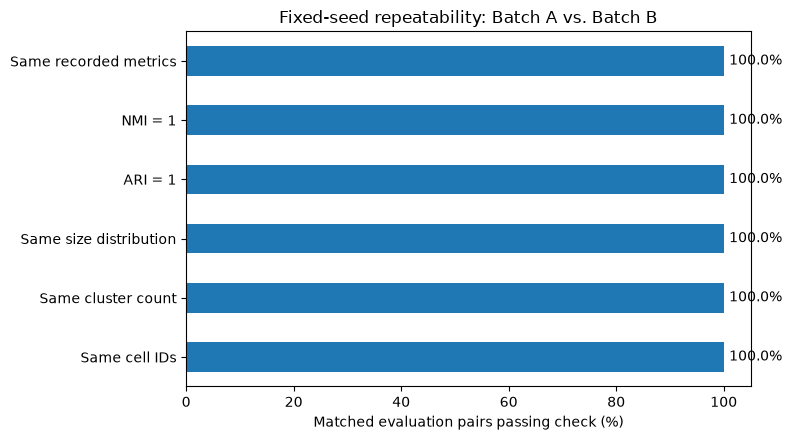

In [8]:
percentages = pd.Series({name: 100 * values.mean() for name, values in checks.items()})
ax = percentages.sort_values().plot(
    kind="barh", figsize=(8, 4.5), xlim=(0, 105),
    xlabel="Matched evaluation pairs passing check (%)",
    title="Fixed-seed repeatability: Batch A vs. Batch B",
)
for bar in ax.patches:
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.1f}%", va="center")
plt.tight_layout()
plt.show()

## 8. Audit exact matches

This audit identifies matched parameter configurations whose clustering results pass all consistency checks: identical cell IDs, matching cluster counts and sorted cluster-size distributions, ARI = 1.0, NMI = 1.0, matching recorded metrics, and agreement between recorded and label-derived cluster counts. Passing all checks indicates that the two partitions are identical, with matching evaluation metrics and metadata.

In [13]:
all_checks_pass = (
    comparison["same_cell_ids"]
    & comparison["same_cluster_count"]
    & comparison["same_cluster_size_distribution"]
    & np.isclose(comparison["ARI"], 1.0)
    & np.isclose(comparison["NMI"], 1.0)
    & comparison["metrics_match"]
    & comparison["labels_batch_agree_with_recorded_counts"]
)

print(f"Pairs passing all checks: {int(all_checks_pass.sum())} / {len(comparison)}")
audit_columns = PARAMS + [
    "run_a", "iteration_a", "leiden_seed_a",
    "run_b", "iteration_b", "leiden_seed_b",
    "recorded_clusters_a", "clusters_from_labels_batch_a",
    "recorded_clusters_b", "clusters_from_labels_batch_b",
    "same_cluster_size_distribution", "ARI", "NMI",
    "metrics_match", "identical_partition",
]


# Sort all passing comparisons
passing_pairs = (
    comparison.loc[all_checks_pass, audit_columns]
    .sort_values(PARAMS + ["run_a", "iteration_a"])
    .reset_index(drop=True)
)

# Sort all failing comparisons
failing_pairs = (
    comparison.loc[~all_checks_pass, audit_columns]
    .sort_values(PARAMS + ["run_a", "iteration_a"])
    .reset_index(drop=True)
)

# Display every row in the notebook
display(passing_pairs)
display(failing_pairs)

# Save both tables as CSV
#passing_pairs.to_csv("fixed_seed_passing_pairs.csv", index=False)
#failing_pairs.to_csv("fixed_seed_failing_pairs.csv", index=False)

#print(f"Passing pairs: {len(passing_pairs)}")
#print(f"Failing pairs: {len(failing_pairs)}")
#print("Saved both CSV files to the current working directory.")


Pairs passing all checks: 117 / 117


,n_neighbors,n_pcs,resolution,run_a,iteration_a,leiden_seed_a,run_b,iteration_b,leiden_seed_b,recorded_clusters_a,clusters_from_labels_batch_a,recorded_clusters_b,clusters_from_labels_batch_b,same_cluster_size_distribution,ARI,NMI,metrics_match,identical_partition
0,15,30,0.7,8,3,42,1,4,42,8,8,8,8,True,1.0,1.0,True,True
1,15,30,0.8,4,1,42,2,1,42,9,9,9,9,True,1.0,1.0,True,True
2,15,30,0.8,4,1,42,3,1,42,9,9,9,9,True,1.0,1.0,True,True
3,15,30,0.8,4,1,42,8,1,42,9,9,9,9,True,1.0,1.0,True,True
4,15,30,0.8,8,1,42,2,1,42,9,9,9,9,True,1.0,1.0,True,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,35,30,1.0,6,2,42,4,2,42,9,9,9,9,True,1.0,1.0,True,True
113,45,10,0.9,6,12,42,6,14,42,10,10,10,10,True,1.0,1.0,True,True
114,45,10,1.0,6,11,42,6,15,42,10,10,10,10,True,1.0,1.0,True,True
115,45,20,1.0,6,6,42,4,5,42,9,9,9,9,True,1.0,1.0,True,True


,n_neighbors,n_pcs,resolution,run_a,iteration_a,leiden_seed_a,run_b,iteration_b,leiden_seed_b,recorded_clusters_a,clusters_from_labels_batch_a,recorded_clusters_b,clusters_from_labels_batch_b,same_cluster_size_distribution,ARI,NMI,metrics_match,identical_partition


Passing pairs: 117
Failing pairs: 0
Saved both CSV files to the current working directory.


**In the fixed-seed comparison, 117 of 117 matched pairs passed all checks, demonstrating exact agreement for the matched comparisons**

## 9. Comparing Final Selections Across Agent Batches


This section addresses optimization stability separately from cell-level partition repeatability.

In [14]:
selection_batch_a = pd.read_csv(batch_a_analysis_dir / "new_final_best_selection_table.csv")
selection_batch_b = pd.read_csv(batch_b_analysis_dir / "new_final_best_selection_table.csv")

selection_columns = [
    "run_index", "selected_iteration", "selected_n_neighbors",
    "selected_n_pcs", "selected_resolution", "n_clusters",
]

print("Batch A selected configurations")
display(selection_batch_a[selection_columns].sort_values("run_index").reset_index(drop=True))
print("Batch B selected configurations")
display(selection_batch_b[selection_columns].sort_values("run_index").reset_index(drop=True))



Batch A selected configurations


,run_index,selected_iteration,selected_n_neighbors,selected_n_pcs,selected_resolution,n_clusters
0,1,6,20,25,0.6,8
1,2,15,25,12,1.1,11
2,3,7,30,10,0.8,10
3,4,12,20,40,0.5,7
4,5,8,15,12,0.8,10
5,6,12,45,10,0.9,10
6,7,7,30,30,0.7,8
7,8,7,15,20,0.6,8


Batch B selected configurations


,run_index,selected_iteration,selected_n_neighbors,selected_n_pcs,selected_resolution,n_clusters
0,1,15,30,20,0.72,9
1,2,7,20,10,0.80,10
2,3,11,25,20,0.50,7
3,4,7,35,20,1.00,9
4,5,14,20,10,0.90,11
5,6,14,45,10,0.90,10
6,7,11,15,10,0.70,10
7,8,12,30,35,0.80,7


Both run 6 has same parameter combination


## 10. Visualize final selected cluster-size distributions

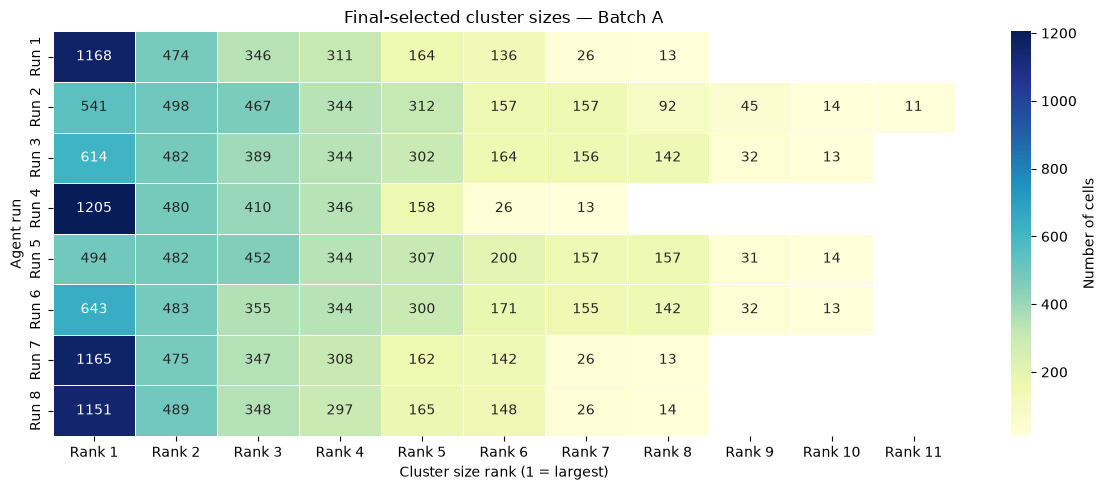

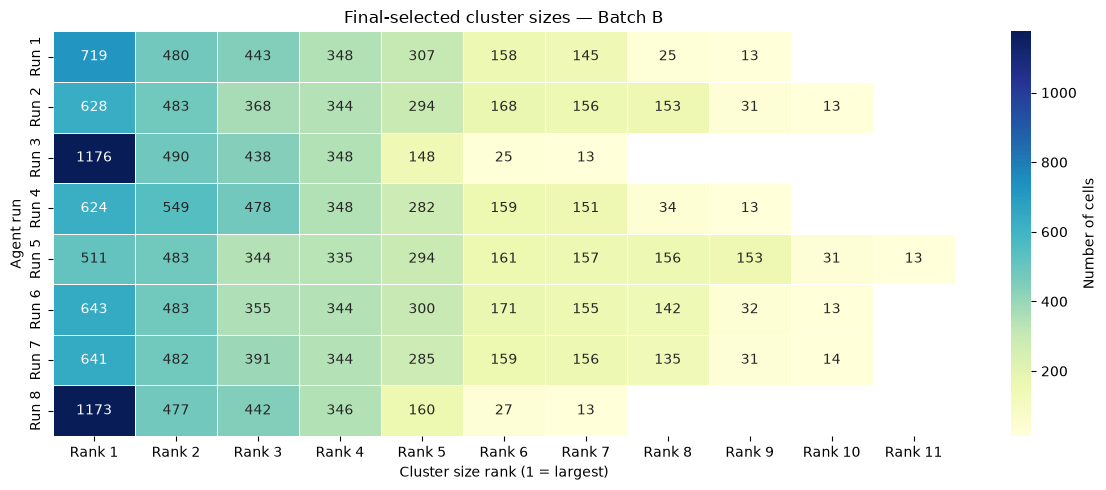

In [15]:
def selected_cluster_size_table(selection_df, batch_dir):
    records = []
    for _, row in selection_df.iterrows():
        labels = load_iteration(
            batch_dir, int(row["run_index"]), int(row["selected_iteration"])
        )
        sizes = sorted(labels.value_counts().tolist(), reverse=True)
        record = {"run_index": int(row["run_index"])}
        record.update({f"cluster_size_rank_{i+1}": size for i, size in enumerate(sizes)})
        records.append(record)
    return pd.DataFrame(records).sort_values("run_index").reset_index(drop=True)

sizes_a = selected_cluster_size_table(selection_batch_a, batch_a_dir)
sizes_b = selected_cluster_size_table(selection_batch_b, batch_b_dir)

for batch_name, size_table in (("A", sizes_a), ("B", sizes_b)):
    heatmap_data = size_table.set_index("run_index")
    heatmap_data.columns = [f"Rank {i}" for i in range(1, len(heatmap_data.columns) + 1)]
    heatmap_data.index = [f"Run {i}" for i in heatmap_data.index]

    plt.figure(figsize=(12, 5))
    sns.heatmap(
        heatmap_data, annot=True, fmt=".0f", cmap="YlGnBu",
        linewidths=0.5, mask=heatmap_data.isna(),
        cbar_kws={"label": "Number of cells"},
    )
    plt.title(f"Final-selected cluster sizes — Batch {batch_name}")
    plt.xlabel("Cluster size rank (1 = largest)")
    plt.ylabel("Agent run")
    plt.tight_layout()
    plt.show()

# These are ranked sizes, not cell-level cluster identities.
# Equal sizes at the same rank do not establish identical partitions.